# 04 · Bring your own model

Kaimei runs some model families itself (scikit-learn linear models, trees and small forests, MLPs, Keras and PyTorch networks), which is what notebooks 01–03 relied on. Many production models are something else: gradient-boosted trees, an ensemble behind an API, a model in another language. This notebook uses **XGBoost**, a model Kaimei can draw but not run, and shows three ways to explain it anyway:

| | You provide | Kaimei gives you |
| --- | --- | --- |
| **A. Your own attributions** | SHAP values you compute (XGBoost has them built in) | stored, browsable explanations next to the model's importance summary |
| **B. A scoring endpoint** | an HTTP endpoint that scores rows | everything: its own explanations, counterfactuals and full analyses, by calling your endpoint |
| **C. Shapes only** | `weights="summary"`: no weights leave your environment | the architecture drawn from shapes and statistics; combine it with B to explain |

**Uses** 1 model (2 with an endpoint), 2 explanations, about 420 logged predictions and, with an endpoint, 1 analysis of a free Kaimei plan.

**Before you start:** `pip install -r requirements.txt` from the repository root, and copy `.env.example` to `.env` with your Kaimei API key (dashboard → **API keys**). The notebook asks for the key if it can't find one.

> **Running on Google Colab or without a clone?** Install this example first; the data downloads by itself:
> ```python
> %pip install -q "titanic-kaimei-example[xgboost,serve] @ git+https://github.com/KaimeiAI/titanic-kaimei-example"
> ```

## 1. Connect and train XGBoost

In [1]:
import os

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost

from kaimei import KaimeiError
from kaimei.tabular import explanation_summary, plot_explanation, plot_insight
from titanic_kaimei import FEATURES, OUTPUTS, encode, load, to_row, to_rows
from titanic_kaimei.models import make_forest, make_xgboost, scores
from titanic_kaimei.serving import create_app, serve_in_background
from titanic_kaimei.workspace import (
    XGBOOST, XGBOOST_REMOTE, connect, dashboard_url, delete_if_exists, ensure_project, replace_model, run_analysis,
)

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

client = connect()
project = ensure_project(client)

titanic = load(1)
X, y = encode(titanic.passengers), (titanic.survived == "survived").astype(int)  # XGBoost wants 0/1 labels
booster_model = make_xgboost()
scores({"XGBoost (200 trees)": booster_model, "Random forest (notebook 01)": make_forest()}, X, y)

Connected to Kaimei at https://api.kaimei.ai (workspace: Kaimei Workspace)


,5-fold CV accuracy,validation accuracy
XGBoost (200 trees),0.836,0.844
Random forest (notebook 01),0.827,0.827


XGBoost is the most accurate model in this repository, and that's typical: the model you most want to ship is often one Kaimei can't run by itself.

## 2. Register it

`client.models.upload` reads whatever it can from the estimator. For XGBoost that's the feature importances, which is enough to draw the model on the dashboard. Kaimei warns that it can't run it:

In [2]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    xgb_model = replace_model(
        client, booster_model, slug=XGBOOST, name="Titanic survival · XGBoost",
        description="200 gradient-boosted trees (depth 4). Explained with XGBoost's own TreeSHAP values.",
        tags=["titanic", "example"], features=FEATURES, feature_names=list(X.columns), outputs=OUTPUTS,
    X=titanic.passengers, y=titanic.survived, project_id=project.id,
    )
for warning in caught:
    print("Kaimei warns:", warning.message)
print(client.models.structure(XGBOOST).summary)

Kaimei warns: This estimator was stored as a sketch or feature-importance summary. Kaimei can visualize it, but explain/predict/analyse need a remote inference URL or pre-computed attributions.


Ensemble of 200 trees. The full split graph is too large to draw node by node; the bars are the fitted feature importances. Upload a single tree to trace an exact path.


Asking Kaimei to explain it says exactly what's missing:

In [3]:
braund = to_row(titanic.passengers.iloc[0])
try:
    client.explanations.create(model=XGBOOST, input=braund, method="shap")
except KaimeiError as error:
    print(f"{error.code}: {error}")

model_not_runnable: This model has no inference configuration, so Kaimei cannot query it. Upload an executable structure (linear, MLP, tree, or small forest), set `inference` to a remote endpoint (`{"type": "remote", "url": ...}`), or send pre-computed attributions with the explanation. [model_not_runnable] (HTTP 422)


## 3. A · Send your own attributions

XGBoost computes exact SHAP values for its own trees (TreeSHAP, `pred_contribs=True`). They're in **log-odds**, the units the trees add up in: the last column is the base value, and base + attributions = the model's raw score for this passenger.

Pass them as `attributions`, with the base value and the output. Kaimei stores the explanation without running the model, and it appears on the dashboard like any other:

method: provided; P(survived) = 3.6%
The model predicts -3.3 log-odds, against -0.48 on average over the reference data. Pulling it down: Sex = male (−1.25), Fare = 7.25 GBP (−0.621), Pclass = 3 (−0.391).


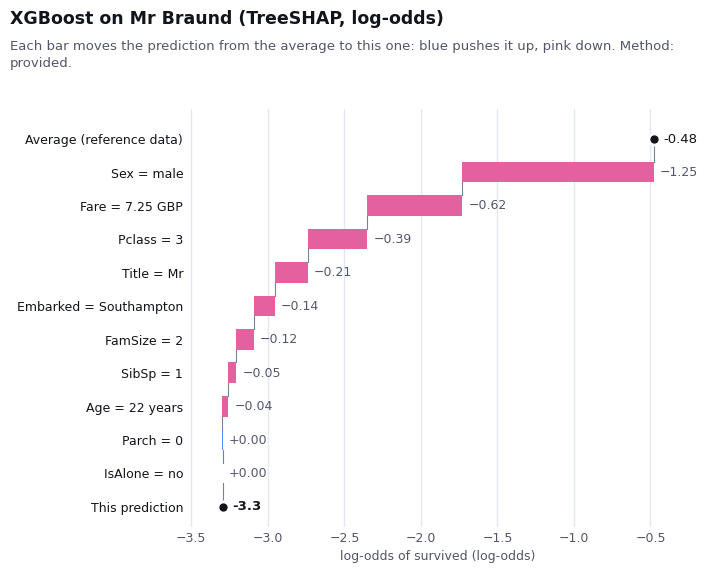

In [4]:
contributions = booster_model.get_booster().predict(xgboost.DMatrix(X.iloc[[0]]), pred_contribs=True)[0]
log_odds = float(contributions.sum())
explanation = client.explanations.create(
    model=XGBOOST,
    input=braund,
    attributions=dict(zip(X.columns, map(float, contributions[:-1]))),
    base_value=float(contributions[-1]),
    output={"value": log_odds, "name": "log-odds of survived", "unit": "log-odds",
            "label": "survived" if log_odds >= 0 else "died", "probability": float(1 / (1 + np.exp(-abs(log_odds))))},
    metadata={"method": "xgboost TreeSHAP"},
)
print(f"method: {explanation.method}; P(survived) = {1 / (1 + np.exp(-log_odds)):.1%}")
print(explanation_summary(explanation, model=xgb_model))
plot_explanation(explanation, model=xgb_model, title="XGBoost on Mr Braund (TreeSHAP, log-odds)")
plt.show()

The story matches the forest's in notebook 01: being a man, a cheap ticket and third class sink his odds. The units differ (log-odds instead of probability points), so compare rankings and signs rather than sizes.

Production traffic is logged the same way as for any model ([notebook 02](02-monitor-in-production.ipynb)), here with each prediction's TreeSHAP values in its metadata, so your own systems can read them back later:

In [5]:
X_new = encode(titanic.new_passengers)
p_new = booster_model.predict_proba(X_new)[:, 1]
new_contributions = booster_model.get_booster().predict(xgboost.DMatrix(X_new), pred_contribs=True)
items = [
    {
        "input": row,
        "output": {"label": "survived" if p >= 0.5 else "died", "value": float(p), "probability": float(max(p, 1 - p))},
        "metadata": {"treeshap": dict(zip(X.columns, np.round(c[:-1], 4).tolist()))},
    }
    for row, p, c in zip(to_rows(titanic.new_passengers), p_new, new_contributions)
]
client.predictions.create_batch(model=XGBOOST, items=items)
print(f"Logged {len(items)} predictions. Mean |TreeSHAP| per feature, in log-odds:")
pd.Series(np.abs(new_contributions[:, :-1]).mean(axis=0), index=X.columns).sort_values(ascending=False).round(3)

Logged 418 predictions. Mean |TreeSHAP| per feature, in log-odds:


Sex         1.392
Pclass      0.604
Fare        0.440
Age         0.278
Title       0.260
SibSp       0.152
Embarked    0.116
FamSize     0.109
Parch       0.017
IsAlone     0.000
dtype: float32

What path A doesn't give you is everything Kaimei computes by *running* the model: counterfactuals, the full analysis (importance, behaviour curves, rules, interactions, robustness, drift) and dashboard what-ifs. Those need path B.

## 4. B · A scoring endpoint

Give Kaimei a URL that scores rows, and it treats the model like one it runs itself: it calls your endpoint in batches whenever it needs a prediction. The contract is small:

```
POST /predict   {"instances": [{"Pclass": 3, "Sex": "male", ...}, ...]}
-> 200          {"predictions": [[P(died), P(survived)], ...]}
```

Rows arrive in the feature schema's own values (`"Sex": "male"`, `"Fare": 7.25`), and probabilities come back in the order of `outputs.labels`. [`src/titanic_kaimei/serving.py`](../src/titanic_kaimei/serving.py) is a complete FastAPI service for this model. Run it on its own with `python -m titanic_kaimei.serving --port 8080`; here it runs on a background thread:

In [6]:
# TITANIC_SCORING_PORT fixes the port, so a tunnel can point at it before the notebook runs.
service_url, server = serve_in_background(create_app(booster_model), port=int(os.environ.get("TITANIC_SCORING_PORT", "0")))
response = httpx.post(f"{service_url}/predict", json={"instances": to_rows(titanic.passengers.head(2))})
print("local service:", service_url)
response.json()

local service: http://127.0.0.1:8765


{'predictions': [[0.9643000364303589, 0.035699959844350815],
  [0.010341107845306396, 0.9896588921546936]]}

Kaimei's servers have to be able to reach the endpoint. A service on your laptop isn't reachable from `api.kaimei.ai` until you expose it, for example with a tunnel (`cloudflared tunnel --url http://127.0.0.1:8080`, or ngrok) or by deploying it next to your model. Start the tunnel on a fixed port, set `TITANIC_SCORING_PORT` to that port and `TITANIC_SCORING_URL` to the tunnel's public address, and re-run this notebook. With a local Kaimei API, the local service works as is.

Registering the endpoint is one more argument to `upload`: `inference` says where to send rows, optionally with `headers` such as an API key for your service.

In [7]:
api = os.environ.get("KAIMEI_BASE_URL", "https://api.kaimei.ai")
public_url = os.environ.get("TITANIC_SCORING_URL")
endpoint = public_url or (service_url if "127.0.0.1" in api or "localhost" in api else None)

if endpoint is None:
    delete_if_exists(client, XGBOOST_REMOTE)
    print("Skipping path B: Kaimei at", api, "can't reach", service_url)
    print("Expose the service (e.g. `cloudflared tunnel --url", service_url + "`), then set TITANIC_SCORING_PORT and TITANIC_SCORING_URL.")
else:
    remote_model = replace_model(
        client, booster_model, slug=XGBOOST_REMOTE, name="Titanic survival · XGBoost (endpoint)",
        description="The same XGBoost model, scored by Kaimei through its HTTP endpoint.",
        tags=["titanic", "example"], features=FEATURES, feature_names=list(X.columns), outputs=OUTPUTS,
        X=titanic.passengers, y=titanic.survived, project_id=project.id,
        inference={"type": "remote", "url": endpoint.rstrip("/") + "/predict"},
    )
    print("registered", XGBOOST_REMOTE, "->", remote_model.inference["url"])

registered titanic-xgboost-remote -> https://teachers-farming-solar-trademarks.trycloudflare.com/predict


Now Kaimei can do everything it did for the forest. Calls to a remote endpoint cost real time, so by default Kaimei keeps explanations cheap: about a thousand rows, over a small background sample. For a stable answer, ask for the full coalition set over more reference rows (`n_samples` and `background_rows`). That's about 16,000 rows, or 64 requests of 256:

16,394 rows scored by the endpoint in 13.9 s
The model predicts died: P(survived) = 3.6%, against 39.9% on average over the reference data. Pulling P(survived) down: Sex = male (−26.1 pts), Pclass = 3 (−5.3 pts), Embarked = Southampton (−2.3 pts).


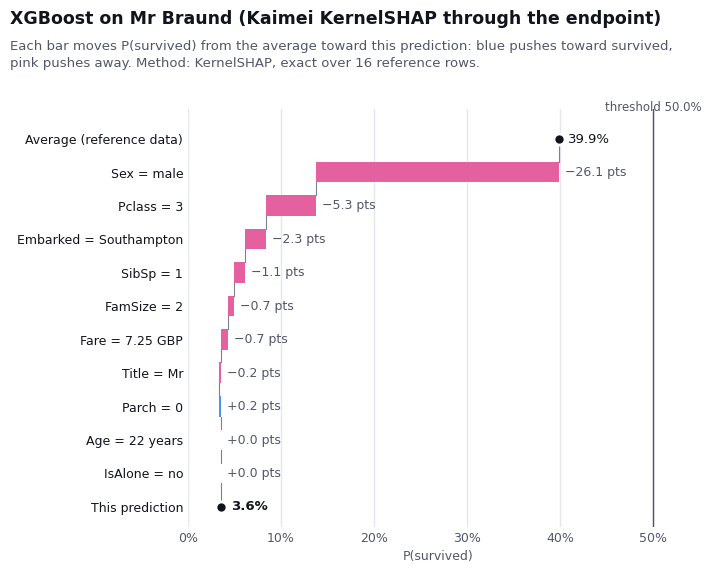

In [8]:
if endpoint is not None:
    remote_explanation = client.explanations.create(
        model=XGBOOST_REMOTE, input=braund, method="shap",
        options={"n_samples": 1024, "background_rows": 16, "seed": 0, "counterfactual": True,
                 "frozen_features": ["Sex", "Age", "Title", "SibSp", "Parch", "FamSize", "IsAlone"]},
    )
    print(f"{remote_explanation.n_evals:,} rows scored by the endpoint in {remote_explanation.latency_ms / 1000:.1f} s")
    print(explanation_summary(remote_explanation, model=remote_model))
    plot_explanation(remote_explanation, model=remote_model, title="XGBoost on Mr Braund (Kaimei KernelSHAP through the endpoint)")
    plt.show()

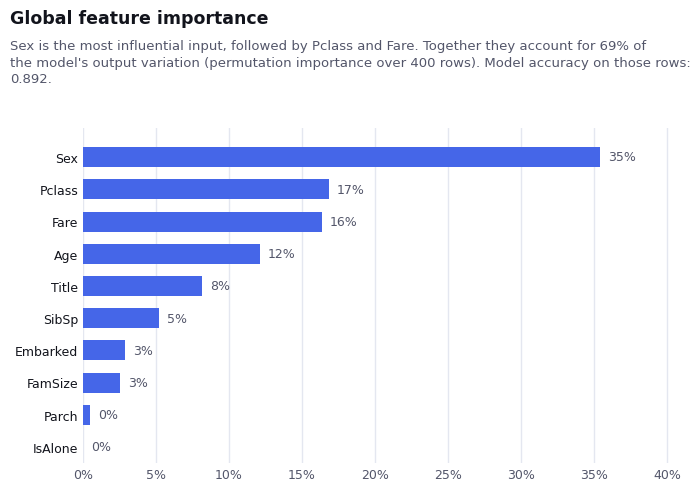

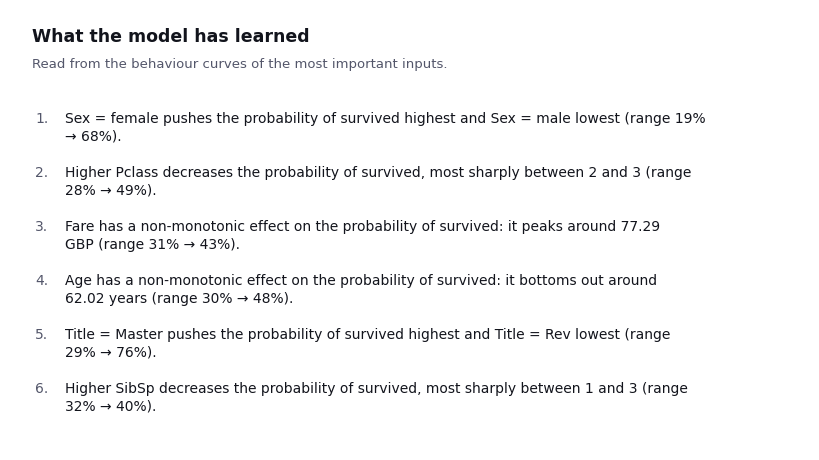

In [9]:
if endpoint is not None:
    remote_insights = run_analysis(client, XGBOOST_REMOTE)
    plot_insight(remote_insights["global_importance"], model=remote_model)
    plt.show()
    plot_insight(remote_insights["learned_rules"], model=remote_model)
    plt.show()

The scoring service lives only as long as this notebook. Once it stops, the endpoint model points at an address nobody answers, and the dashboard would fail to explain it. So the notebook removes it, along with its explanations and analysis. A model behind a service you keep running stays registered.

In [10]:
server.should_exit = True  # stop the local scoring service...
if endpoint is not None:
    delete_if_exists(client, XGBOOST_REMOTE)  # ...and the model that called it

## 5. C · Keep the weights at home

Some models can't leave your environment. `weights="summary"` uploads layer shapes and weight statistics only, so the dashboard can still draw the architecture, and every explanation goes through the endpoint from path B:

```python
client.models.upload(
    model, name="Credit risk v7", features=FEATURES, outputs=OUTPUTS,
    weights="summary",
    inference={"type": "remote", "url": "https://scoring.internal.example.com/predict",
               "headers": {"Authorization": "Bearer ..."}},
)
```

## 6. Which path for which model

- **Kaimei runs it** (scikit-learn linear models, trees, forests of up to 30 trees and MLPs; Keras and PyTorch networks): upload it, as in notebook 01.
- **You already compute SHAP values** (XGBoost, LightGBM and CatBoost all have TreeSHAP built in): path A, with predictions logged for monitoring.
- **Anything you can put behind HTTP**: path B. It unlocks counterfactuals and analyses, and works for any language or framework.
- **Weights must stay private**: path C, plus B.

Every call in these notebooks is also plain REST (`POST https://api.kaimei.ai/v1/explanations`, `/v1/predictions/batch`, ...), so a service in any language can log and explain.

In [11]:
print(dashboard_url(f"models/{XGBOOST}"))
print(dashboard_url("projects/titanic"))

https://dashboard.kaimei.ai/models/titanic-xgboost
https://dashboard.kaimei.ai/projects/titanic
